# Optimalidad: mínimos, convexidad y puntos silla

El descenso de gradiente se detiene cuando el gradiente vale cero. La pregunta de este notebook es qué garantiza eso: ¿el punto donde se detuvo es el mejor posible, uno bueno entre varios, o ni siquiera un mínimo?

La respuesta depende de la forma de la función de pérdida. Para una neurona hay garantías completas. Para una red, no, y conviene entender por qué.

**Contenido**

1. Qué significa "óptimo"
2. Condiciones de optimalidad en una dimensión
3. Varias dimensiones: el hessiano
4. Convexidad
5. La pérdida de una neurona es convexa
6. La solución exacta: ecuaciones normales
7. Número de condición y velocidad del descenso
8. Funciones no convexas: el punto de partida importa
9. Puntos silla
10. La pérdida de una red no es convexa
11. Qué significa esto en la práctica
12. Resumen y ejercicios

In [1]:
import numpy as np
import torch
from torch import nn
from torch.autograd.functional import hessian
import matplotlib.pyplot as plt

torch.manual_seed(42)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 1. Qué significa "óptimo"

Sea $f$ la función que queremos minimizar y $\theta$ sus parámetros.

- $\theta^*$ es un **mínimo global** si $f(\theta^*) \le f(\theta)$ para **todo** $\theta$. Es el mejor valor posible.
- $\theta^*$ es un **mínimo local** si $f(\theta^*) \le f(\theta)$ para todo $\theta$ **suficientemente cercano**. Es el mejor de su vecindario, pero puede haber algo mejor más lejos.

Todo mínimo global es también local. Lo contrario no es cierto.

El descenso de gradiente solo mira el vecindario inmediato (el gradiente es información local), así que por sí solo no distingue un mínimo local de uno global.

## 2. Condiciones de optimalidad en una dimensión

Usamos una función con más de un mínimo:

$$g(x) = x^4 - 3x^2 + x$$

**Condición de primer orden (necesaria).** Si $x^*$ es un mínimo local, entonces $g'(x^*) = 0$. Si la derivada no fuera cero, moverse un poco en contra de su signo bajaría la función y $x^*$ no sería mínimo.

Los puntos donde la derivada es cero se llaman **puntos críticos**. Que la condición sea *necesaria* significa que todo mínimo es un punto crítico, pero no todo punto crítico es un mínimo: los máximos también tienen derivada cero.

**Condición de segundo orden.** La segunda derivada mide la curvatura y permite clasificar un punto crítico:

- $g''(x^*) > 0$: la función se curva hacia arriba. Es un **mínimo local**.
- $g''(x^*) < 0$: se curva hacia abajo. Es un **máximo local**.
- $g''(x^*) = 0$: el criterio no decide.

Aquí $g'(x) = 4x^3 - 6x + 1$ y $g''(x) = 12x^2 - 6$. Buscamos las raíces de $g'$ y clasificamos cada una.

x = -1.301   g(x) = -3.514   g''(x) =  14.31   ->  mínimo local
x =  0.170   g(x) =  0.084   g''(x) =  -5.65   ->  máximo local
x =  1.131   g(x) = -1.070   g''(x) =   9.35   ->  mínimo local


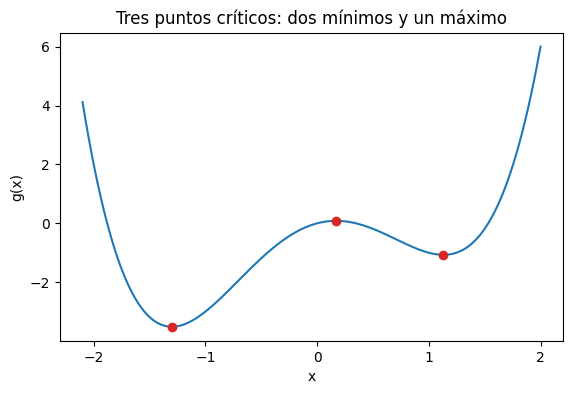

In [2]:
def g(x):
    return x ** 4 - 3 * x ** 2 + x


def g_segunda(x):
    return 12 * x ** 2 - 6


puntos_criticos = np.sort(np.roots([4, 0, -6, 1]).real)      # raíces de g'(x) = 4x^3 - 6x + 1

for p in puntos_criticos:
    tipo = "mínimo local" if g_segunda(p) > 0 else "máximo local"
    print(f"x = {p:6.3f}   g(x) = {g(p):6.3f}   g''(x) = {g_segunda(p):6.2f}   ->  {tipo}")

x = torch.linspace(-2.1, 2.0, 300)
plt.figure(figsize=(6.5, 4))
plt.plot(x, g(x))
plt.scatter(puntos_criticos, g(puntos_criticos), color="tab:red", zorder=3)
plt.xlabel("x")
plt.ylabel("g(x)")
plt.title("Tres puntos críticos: dos mínimos y un máximo")
plt.show()

Hay tres puntos con derivada cero. Dos son mínimos locales, y de ellos solo el de la izquierda es el mínimo global. El del medio es un máximo local.

Un algoritmo que se detiene cuando la derivada es cero podría parar en cualquiera de los tres.

## 3. Varias dimensiones: el hessiano

Con varios parámetros la condición de primer orden es que **todas** las derivadas parciales sean cero:

$$\nabla f(\theta^*) = 0$$

El papel de la segunda derivada lo toma el **hessiano**, la matriz de todas las segundas derivadas:

$$H = \begin{pmatrix} \dfrac{\partial^2 f}{\partial \theta_1^2} & \dfrac{\partial^2 f}{\partial \theta_1 \partial \theta_2} \\[2ex] \dfrac{\partial^2 f}{\partial \theta_2 \partial \theta_1} & \dfrac{\partial^2 f}{\partial \theta_2^2} \end{pmatrix}$$

En varias dimensiones la curvatura depende de la dirección en que se mire. Los **autovalores** del hessiano son las curvaturas en sus direcciones principales (los autovectores), y con ellos se clasifica un punto crítico:

| Autovalores del hessiano | Tipo de punto crítico |
|---|---|
| Todos positivos | **mínimo local**: sube en todas las direcciones |
| Todos negativos | **máximo local**: baja en todas las direcciones |
| Algunos positivos y otros negativos | **punto silla**: sube en unas direcciones y baja en otras |
| Alguno igual a cero (y el resto del mismo signo) | el criterio no decide |

El punto silla es el caso nuevo respecto de una dimensión. Probamos con tres funciones cuyo punto crítico está en el origen. `torch.autograd.functional.hessian` calcula el hessiano con autograd.

In [3]:
def cuenco(p):
    return p[0] ** 2 + p[1] ** 2


def cerro(p):
    return -p[0] ** 2 - p[1] ** 2


def silla(p):
    return p[0] ** 2 - p[1] ** 2


def clasificar(funcion, punto):
    H = hessian(funcion, punto)
    autovalores = torch.linalg.eigvalsh(H)          # autovalores de una matriz simétrica
    if (autovalores > 0).all():
        tipo = "mínimo local"
    elif (autovalores < 0).all():
        tipo = "máximo local"
    elif (autovalores > 0).any() and (autovalores < 0).any():
        tipo = "punto silla"
    else:
        tipo = "el criterio no decide"
    return autovalores, tipo


origen = torch.zeros(2)
funciones = {"x² + y²": cuenco, "-x² - y²": cerro, "x² - y²": silla}

for nombre, funcion in funciones.items():
    autovalores, tipo = clasificar(funcion, origen)
    print(f"{nombre:9s}  autovalores = {autovalores.tolist()}  ->  {tipo}")

x² + y²    autovalores = [2.0, 2.0]  ->  mínimo local
-x² - y²   autovalores = [-2.0, -2.0]  ->  máximo local
x² - y²    autovalores = [-2.0, 2.0]  ->  punto silla


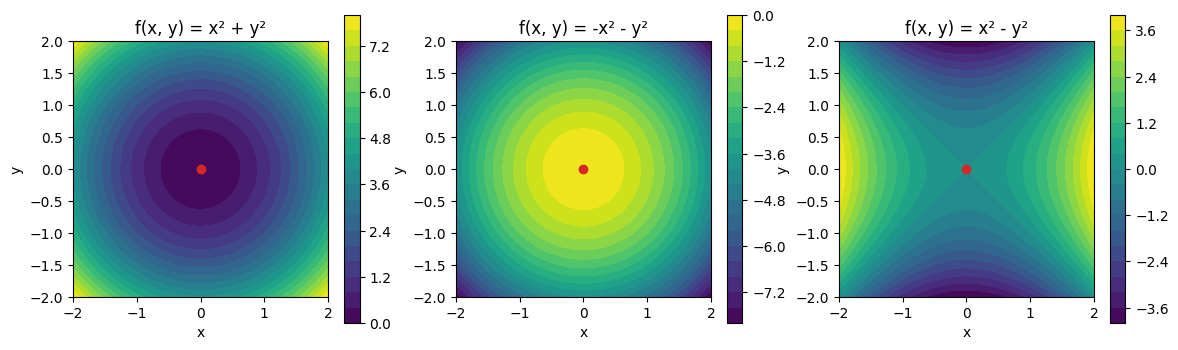

In [4]:
eje_x = torch.linspace(-2, 2, 100)
GX, GY = torch.meshgrid(eje_x, eje_x, indexing="xy")

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, (nombre, funcion) in zip(ejes, funciones.items()):
    Z = funcion(torch.stack([GX, GY]))
    mapa = eje.contourf(GX, GY, Z, levels=20, cmap="viridis")
    eje.scatter([0], [0], color="tab:red", zorder=3)
    eje.set_title(f"f(x, y) = {nombre}")
    eje.set_xlabel("x")
    eje.set_ylabel("y")
    eje.set_aspect("equal")
    fig.colorbar(mapa, ax=eje)
plt.show()

En los tres casos el gradiente en el origen es cero. La diferencia está en la curvatura. En la silla, moverse sobre el eje $x$ sube la función y moverse sobre el eje $y$ la baja: el origen es un mínimo si solo miras una dirección y un máximo si miras la otra.

## 4. Convexidad

Una función es **convexa** si el segmento que une dos puntos cualesquiera de su gráfico nunca queda por debajo del gráfico. Con fórmula: para todo par de puntos $a$, $b$ y todo $\lambda \in [0, 1]$,

$$f(\lambda a + (1 - \lambda) b) \le \lambda f(a) + (1 - \lambda) f(b)$$

El lado izquierdo es la función evaluada en un punto intermedio entre $a$ y $b$. El lado derecho es la altura del segmento en ese mismo punto.

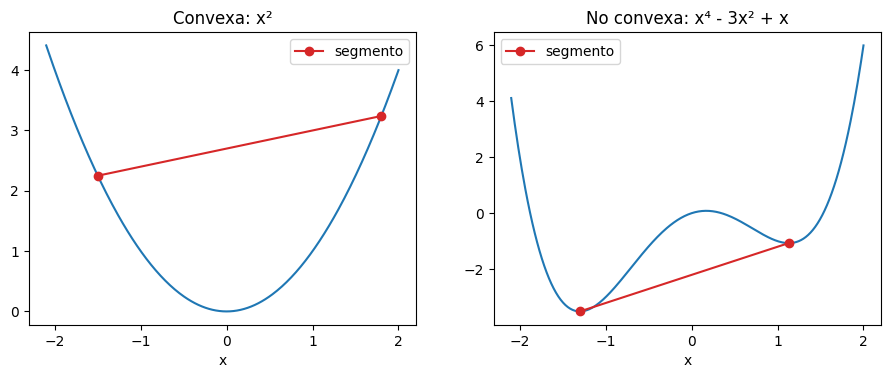

In [5]:
def dibujar_cuerda(eje, funcion, a, b):
    eje.plot([a, b], [funcion(a), funcion(b)], color="tab:red", marker="o", label="segmento")


x = torch.linspace(-2.1, 2.0, 300)
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))

ejes[0].plot(x, x ** 2)
dibujar_cuerda(ejes[0], lambda v: v ** 2, -1.5, 1.8)
ejes[0].set_title("Convexa: x²")

ejes[1].plot(x, g(x))
dibujar_cuerda(ejes[1], g, -1.3, 1.13)
ejes[1].set_title("No convexa: x⁴ - 3x² + x")

for eje in ejes:
    eje.set_xlabel("x")
    eje.legend()
plt.show()

A la izquierda el segmento queda siempre sobre la curva. A la derecha, entre los dos mínimos la curva sube por encima del segmento: la función no es convexa.

Para funciones con segundas derivadas hay un criterio equivalente y más fácil de verificar: $f$ es convexa si y solo si su hessiano no tiene autovalores negativos **en ningún punto** (en una dimensión, $f'' \ge 0$ en todas partes). Es decir, nunca se curva hacia abajo.

La convexidad importa por dos consecuencias:

1. **Todo mínimo local es global.** No existen mínimos "de segunda".
2. **$\nabla f = 0$ es suficiente.** En una función convexa todo punto crítico es un mínimo global. No hay puntos silla ni máximos locales estrictos donde quedar atrapado.

En una función convexa, entonces, si el descenso de gradiente converge, lo hace al mejor valor posible, sin importar desde dónde parta.

## 5. La pérdida de una neurona es convexa

Volvemos a la neurona con MSE y las diez entregas del módulo 01. Para trabajar con matrices, juntamos los parámetros en un vector $\theta = (w, b)$ y armamos una matriz $A$ con una fila $(x_i, 1)$ por ejemplo. Así $A\theta$ es el vector de todas las predicciones, y la pérdida se escribe

$$L(\theta) = \frac{1}{N} \lVert A\theta - y \rVert^2$$

Derivando dos veces:

$$\nabla L(\theta) = \frac{2}{N} A^\top (A\theta - y) \qquad\qquad H = \frac{2}{N} A^\top A$$

Dos observaciones sobre este hessiano:

- **No depende de $\theta$.** La curvatura es la misma en todos los puntos, porque la pérdida es una función cuadrática.
- **No tiene autovalores negativos.** Para cualquier dirección $v$ se cumple $v^\top H v = \frac{2}{N} \lVert Av \rVert^2 \ge 0$, porque es una norma al cuadrado.

Por el criterio de la sección anterior, **la pérdida MSE de un modelo lineal es convexa**. Lo verificamos calculando el hessiano con la fórmula y con autograd:

In [6]:
distancias = torch.tensor([1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5])
tiempos = torch.tensor([7.3, 9.1, 12.4, 14.2, 17.5, 19.0, 22.6, 24.1, 27.4, 29.2])
N = len(distancias)

A = torch.stack([distancias, torch.ones(N)], dim=1)       # forma [10, 2]: columnas x y unos


def perdida_neurona(theta):
    return ((A @ theta - tiempos) ** 2).mean()


H_formula = 2 / N * A.T @ A
H_autograd = hessian(perdida_neurona, torch.zeros(2))

print("Hessiano con la fórmula:\n", H_formula)
print("Hessiano con autograd:\n", H_autograd)

autovalores = torch.linalg.eigvalsh(H_formula)
print("\nAutovalores:", autovalores.tolist())

Hessiano con la fórmula:
 tensor([[25.2500,  6.5000],
        [ 6.5000,  2.0000]])
Hessiano con autograd:
 tensor([[25.2500,  6.5000],
        [ 6.5000,  2.0000]])

Autovalores: [0.30619287490844727, 26.94380760192871]


Los dos autovalores son positivos. La superficie de pérdida es un cuenco con un único mínimo, que es global. Es el valle que dibujamos en `02-descenso-de-gradiente`: el autovalor grande es la curvatura al cruzar el valle y el pequeño la curvatura a lo largo.

Ahora se puede explicar el umbral de la tasa de aprendizaje que apareció en ese notebook. En una dimensión, el descenso converge si $\eta < 2 / \text{curvatura}$. En varias dimensiones manda la dirección más curva:

$$\eta < \frac{2}{\lambda_{\max}}$$

In [7]:
print(f"Cota para la tasa de aprendizaje: 2 / {autovalores.max():.3f} = {2 / autovalores.max():.4f}")

Cota para la tasa de aprendizaje: 2 / 26.944 = 0.0742


Coincide con lo observado: con `lr = 0.073` convergía y con `lr = 0.075` divergía.

## 6. La solución exacta: ecuaciones normales

Como la pérdida es convexa, la condición $\nabla L = 0$ identifica el mínimo global. Igualando el gradiente a cero:

$$\frac{2}{N} A^\top (A\theta - y) = 0 \quad\Longleftrightarrow\quad A^\top A \, \theta = A^\top y$$

Estas son las **ecuaciones normales**: un sistema lineal de dos ecuaciones con dos incógnitas. Se resuelve directamente, sin iterar.

In [8]:
theta_optimo = torch.linalg.solve(A.T @ A, A.T @ tiempos)

print(f"Solución exacta: w = {theta_optimo[0]:.4f}, b = {theta_optimo[1]:.4f}")
print(f"Pérdida mínima : {perdida_neurona(theta_optimo):.4f}")

gradiente = 2 / N * A.T @ (A @ theta_optimo - tiempos)
print(f"Gradiente en la solución: {gradiente.tolist()}")

Solución exacta: w = 4.9745, b = 2.1127
Pérdida mínima : 0.1748
Gradiente en la solución: [4.196708687231876e-06, -4.812397946807323e-07]


El gradiente es cero salvo por errores de redondeo. En el módulo 01 la neurona entrenada llegó a $w \approx 4.97$ y $b \approx 2.11$ con pérdida 0.1748: el descenso de gradiente encontró el mínimo global, y ahora sabemos que no fue suerte.

Si existe una solución exacta, ¿para qué iterar? Porque resolver el sistema cuesta del orden de $d^3$ operaciones para $d$ parámetros, lo que es inviable con millones, y sobre todo porque **esta fórmula solo existe para modelos lineales con MSE**. En cuanto hay una capa oculta con activación, $\nabla L = 0$ deja de ser un sistema lineal y, en general, no tiene solución cerrada. El descenso de gradiente sigue funcionando igual.

En la práctica se prefiere `torch.linalg.lstsq(A, y)`, que resuelve el mismo problema de forma numéricamente más estable que formar $A^\top A$.

## 7. Número de condición y velocidad del descenso

Que la función sea convexa garantiza a dónde se llega, pero no cuánto se demora. Eso lo decide el **número de condición** del hessiano:

$$\kappa = \frac{\lambda_{\max}}{\lambda_{\min}}$$

Compara la dirección más curva con la más plana. Si $\kappa = 1$ la superficie es un cuenco redondo; si $\kappa$ es grande, un valle angosto.

Para una función cuadrática se puede demostrar que, con la mejor tasa fija posible, $\eta = 2 / (\lambda_{\max} + \lambda_{\min})$, la distancia al óptimo se multiplica en cada paso por un factor que, en el peor caso, vale

$$\frac{\kappa - 1}{\kappa + 1}$$

Mientras más grande es $\kappa$, más cerca de 1 está ese factor y más lento es el avance. Comparamos los datos sin normalizar y con la entrada estandarizada:

In [9]:
def numero_de_condicion(x):
    A = torch.stack([x, torch.ones(len(x))], dim=1)
    autovalores = torch.linalg.eigvalsh(2 / len(x) * A.T @ A)
    return autovalores, (autovalores.max() / autovalores.min()).item()


x_norm = (distancias - distancias.mean()) / distancias.std()

for nombre, entrada in [("sin normalizar", distancias), ("estandarizada", x_norm)]:
    autovalores, kappa = numero_de_condicion(entrada)
    factor = (kappa - 1) / (kappa + 1)
    print(f"{nombre:15s} autovalores = {[round(v, 3) for v in autovalores.tolist()]}   "
          f"kappa = {kappa:6.2f}   factor por paso = {factor:.3f}")

sin normalizar  autovalores = [0.306, 26.944]   kappa =  88.00   factor por paso = 0.978
estandarizada   autovalores = [1.8, 2.0]   kappa =   1.11   factor por paso = 0.053


Sin normalizar, el error se reduce apenas un par de puntos porcentuales por paso en el mejor de los casos. Con la entrada estandarizada el número de condición es casi 1 y cada paso elimina la mayor parte del error. Esa es la justificación matemática de normalizar los datos: no cambia el modelo ni su óptimo, cambia la geometría del problema.

## 8. Funciones no convexas: el punto de partida importa

Volvemos a $g(x) = x^4 - 3x^2 + x$, que no es convexa, y corremos el descenso de gradiente desde tres puntos de partida.

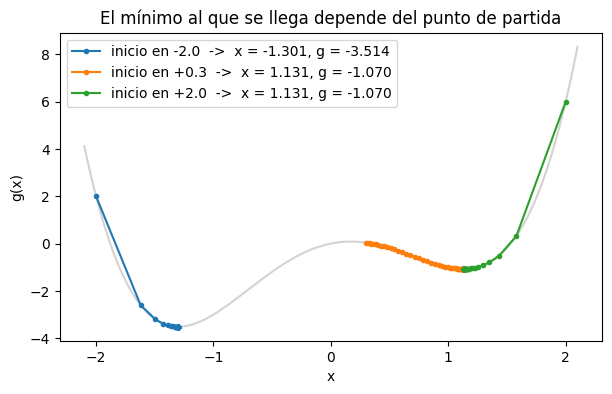

In [10]:
def descenso_g(x_inicial, lr=0.02, pasos=300):
    x = torch.tensor(x_inicial, requires_grad=True)
    trayectoria = [x.item()]
    for _ in range(pasos):
        g(x).backward()
        with torch.no_grad():
            x -= lr * x.grad
        x.grad.zero_()
        trayectoria.append(x.item())
    return torch.tensor(trayectoria)


x = torch.linspace(-2.1, 2.1, 300)
plt.figure(figsize=(7, 4))
plt.plot(x, g(x), color="lightgray")

for x_inicial, color in [(-2.0, "tab:blue"), (0.3, "tab:orange"), (2.0, "tab:green")]:
    tray = descenso_g(x_inicial)
    plt.plot(tray, g(tray), marker="o", markersize=3, color=color,
             label=f"inicio en {x_inicial:+.1f}  ->  x = {tray[-1].item():.3f}, g = {g(tray[-1]).item():.3f}")

plt.xlabel("x")
plt.ylabel("g(x)")
plt.title("El mínimo al que se llega depende del punto de partida")
plt.legend()
plt.show()

Mismo algoritmo, misma función, misma tasa de aprendizaje. Partiendo desde la izquierda se llega al mínimo global; desde los otros dos puntos, al mínimo local, que es peor. En todos los casos el gradiente final es cero y el algoritmo "terminó bien".

Cada mínimo tiene su **cuenca de atracción**: el conjunto de puntos de partida que terminan en él. En una función no convexa, la inicialización decide el resultado. Por eso en redes neuronales los pesos iniciales (y la semilla que los genera) influyen en el modelo final.

## 9. Puntos silla

El otro obstáculo de las funciones no convexas son los puntos silla. Usamos

$$h(x, y) = x^2 + \frac{y^4}{4} - \frac{y^2}{2}$$

Su gradiente es $\nabla h = (2x, \; y^3 - y)$, que se anula en tres puntos: $(0, 0)$, $(0, 1)$ y $(0, -1)$. Los clasificamos con el hessiano:

In [11]:
def h(p):
    return p[0] ** 2 + p[1] ** 4 / 4 - p[1] ** 2 / 2


for punto in [(0.0, 0.0), (0.0, 1.0), (0.0, -1.0)]:
    autovalores, tipo = clasificar(h, torch.tensor(punto))
    print(f"punto {punto}   h = {h(torch.tensor(punto)).item():6.3f}   autovalores = {autovalores.tolist()}  ->  {tipo}")

punto (0.0, 0.0)   h =  0.000   autovalores = [-1.0, 2.0]  ->  punto silla
punto (0.0, 1.0)   h = -0.250   autovalores = [2.0, 2.0]  ->  mínimo local
punto (0.0, -1.0)   h = -0.250   autovalores = [2.0, 2.0]  ->  mínimo local


El origen es un punto silla y los otros dos son mínimos. Corremos el descenso de gradiente desde tres situaciones:

- Partiendo exactamente sobre el eje $x$, donde $y = 0$.
- Partiendo a una distancia minúscula de ese eje.
- Partiendo sobre el eje, pero sumando un poco de ruido al gradiente en cada paso, como hace SGD.

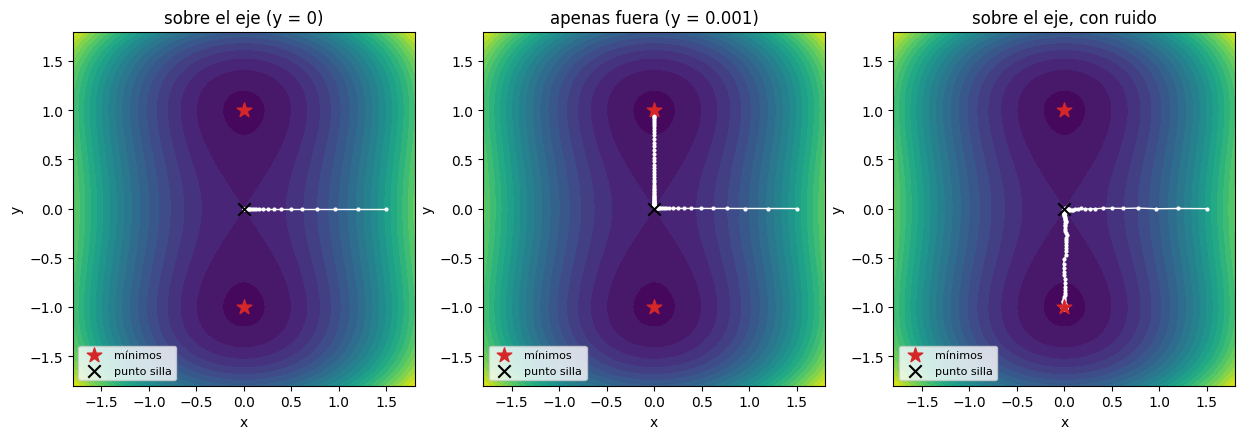

sobre el eje (y = 0)       termina en ( 0.000,  0.000)   h =  0.0000
apenas fuera (y = 0.001)   termina en ( 0.000,  1.000)   h = -0.2500
sobre el eje, con ruido    termina en (-0.005, -1.004)   h = -0.2500


In [12]:
def descenso_h(inicio, lr=0.1, pasos=200, ruido=0.0, semilla=0):
    generador = torch.Generator().manual_seed(semilla)
    p = torch.tensor(inicio, requires_grad=True)
    trayectoria = [p.detach().clone()]
    for _ in range(pasos):
        h(p).backward()
        with torch.no_grad():
            p -= lr * (p.grad + ruido * torch.randn(2, generator=generador))
        p.grad.zero_()
        trayectoria.append(p.detach().clone())
    return torch.stack(trayectoria)


casos = {
    "sobre el eje (y = 0)": descenso_h((1.5, 0.0)),
    "apenas fuera (y = 0.001)": descenso_h((1.5, 0.001)),
    "sobre el eje, con ruido": descenso_h((1.5, 0.0), ruido=0.05),
}

eje_x = torch.linspace(-1.8, 1.8, 120)
GX, GY = torch.meshgrid(eje_x, eje_x, indexing="xy")
Z = h(torch.stack([GX, GY]))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6))
for eje, (nombre, tray) in zip(ejes, casos.items()):
    eje.contourf(GX, GY, Z, levels=25, cmap="viridis")
    eje.plot(tray[:, 0], tray[:, 1], color="white", marker="o", markersize=2, linewidth=1)
    eje.scatter([0, 0], [1, -1], color="tab:red", marker="*", s=120, zorder=3, label="mínimos")
    eje.scatter([0], [0], color="black", marker="x", s=80, zorder=3, label="punto silla")
    eje.set_title(nombre)
    eje.set_xlabel("x")
    eje.set_ylabel("y")
    eje.legend(loc="lower left", fontsize=8)
plt.show()

for nombre, tray in casos.items():
    final = tray[-1]
    print(f"{nombre:26s} termina en ({final[0]:6.3f}, {final[1]:6.3f})   h = {h(final).item():7.4f}")

- **Sobre el eje**, la componente $y$ del gradiente es exactamente cero en todo el camino. El descenso baja hasta el punto silla y se queda ahí, con gradiente cero, convencido de haber terminado. Pero $h = 0$ en ese punto y los mínimos valen $-0.25$.
- **Apenas fuera del eje**, la pequeña componente en $y$ se amplifica paso a paso, porque en esa dirección la curvatura es negativa, y la trayectoria termina en un mínimo. Eso sí, pasa muchos pasos casi detenida cerca de la silla antes de escapar.
- **Con ruido**, aunque parta sobre el eje, el ruido la saca de ahí y escapa.

Tres conclusiones:

1. Quedar atrapado *exactamente* en un punto silla requiere una coincidencia improbable. El problema real es que cerca de ellos el gradiente es muy pequeño y el entrenamiento **se frena**: la pérdida se queda en una meseta que parece convergencia y no lo es.
2. El **ruido de SGD ayuda** a salir de los puntos silla. Lo que en el notebook de SGD parecía solo un costo aquí es una ventaja.
3. En problemas con muchos parámetros se espera que los puntos silla sean mucho más frecuentes que los mínimos locales malos. El argumento es heurístico: para que un punto crítico sea mínimo, la curvatura tiene que ser positiva en *todas* las direcciones a la vez, y con millones de direcciones eso es raro.

## 10. La pérdida de una red no es convexa

Para la neurona demostramos convexidad. Para una red con capa oculta vamos a demostrar lo contrario, con un argumento que no requiere dibujar nada.

Tomamos la red del módulo 01 (1 entrada, 8 neuronas ocultas con ReLU, 1 salida) y los mismos datos con quiebre, y la entrenamos igual que allá.

In [13]:
torch.manual_seed(0)
distancias_2 = torch.linspace(0.5, 20, 60).unsqueeze(1)
tiempo_real = torch.where(distancias_2 <= 5, 6 * distancias_2, 30 + 2 * (distancias_2 - 5))
tiempos_2 = tiempo_real + torch.randn_like(distancias_2)

X = (distancias_2 - distancias_2.mean()) / distancias_2.std()
y = (tiempos_2 - tiempos_2.mean()) / tiempos_2.std()


def entrenar_red(semilla, epocas=3000, lr=0.1):
    torch.manual_seed(semilla)
    red = nn.Sequential(nn.Linear(1, 8), nn.ReLU(), nn.Linear(8, 1))
    optimizador = torch.optim.SGD(red.parameters(), lr=lr)
    for _ in range(epocas):
        perdida = nn.functional.mse_loss(red(X), y)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
    return red, perdida.item()


red, perdida_final = entrenar_red(semilla=42)
print(f"Pérdida de la red entrenada: {perdida_final:.5f}")

Pérdida de la red entrenada: 0.00362


**Simetría de permutación.** Las neuronas de la capa oculta no tienen un orden especial. Si se intercambian dos de ellas (con todos sus pesos de entrada y de salida), la red calcula exactamente la misma función, porque la capa de salida suma los mismos términos en otro orden.

Entonces, a partir de los parámetros entrenados $\theta_A$ podemos construir otros parámetros $\theta_B$ reordenando las neuronas ocultas. Son puntos **distintos** en el espacio de parámetros, con **la misma pérdida**.

Escribimos la red como una función explícita de sus parámetros para poder evaluarla en cualquier punto:

In [14]:
def perdida_red(parametros):
    W1, b1, W2, b2 = parametros
    oculta = torch.relu(X @ W1.T + b1)          # capa oculta + ReLU
    prediccion = oculta @ W2.T + b2             # capa de salida
    return ((prediccion - y) ** 2).mean().item()


W1, b1, W2, b2 = [p.detach().clone() for p in red.parameters()]
theta_A = [W1, b1, W2, b2]

orden = torch.arange(7, -1, -1)                 # invertir el orden de las 8 neuronas ocultas
theta_B = [W1[orden], b1[orden], W2[:, orden], b2]

print(f"Pérdida en theta_A: {perdida_red(theta_A):.5f}")
print(f"Pérdida en theta_B: {perdida_red(theta_B):.5f}")
print(f"¿Son los mismos parámetros? {torch.equal(theta_A[0], theta_B[0])}")

Pérdida en theta_A: 0.00362
Pérdida en theta_B: 0.00362
¿Son los mismos parámetros? False


Ahora recorremos el segmento recto que une $\theta_A$ con $\theta_B$ y evaluamos la pérdida en el camino:

$$\theta(\alpha) = (1 - \alpha) \, \theta_A + \alpha \, \theta_B \qquad \alpha \in [0, 1]$$

Si la pérdida fuera convexa, por la definición de la sección 4 su valor en todo el segmento tendría que ser menor o igual que el de los extremos.

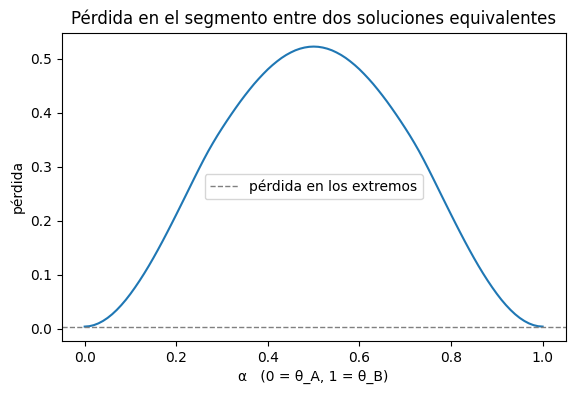

Pérdida en los extremos : 0.00362
Pérdida máxima en medio : 0.52247


In [15]:
alfas = torch.linspace(0, 1, 101)
perdidas = [perdida_red([(1 - a) * pA + a * pB for pA, pB in zip(theta_A, theta_B)]) for a in alfas]

plt.figure(figsize=(6.5, 4))
plt.plot(alfas, perdidas)
plt.axhline(perdida_red(theta_A), color="gray", linestyle="--", linewidth=1, label="pérdida en los extremos")
plt.xlabel("α   (0 = θ_A, 1 = θ_B)")
plt.ylabel("pérdida")
plt.title("Pérdida en el segmento entre dos soluciones equivalentes")
plt.legend()
plt.show()

print(f"Pérdida en los extremos : {perdidas[0]:.5f}")
print(f"Pérdida máxima en medio : {max(perdidas):.5f}")

La pérdida en el interior del segmento es mayor que en los extremos. Eso contradice la definición de convexidad, así que **la pérdida de esta red no es convexa**. Es una demostración, no una ilustración: basta un segmento que viole la desigualdad.

El mismo argumento dice algo más. Con 8 neuronas ocultas hay $8! = 40\,320$ formas de ordenarlas, y, mientras las neuronas sean distintas entre sí, cada una es un punto distinto con la misma pérdida. Si uno de ellos es un mínimo, todos lo son: los mínimos de una red no son únicos.

Además de esas copias equivalentes, entrenar con distintas inicializaciones lleva a soluciones que no son reordenamientos unas de otras:

In [16]:
for semilla in [0, 1, 2, 42]:
    red_s, perdida_s = entrenar_red(semilla)
    quiebres = (-red_s[0].bias / red_s[0].weight.squeeze()).detach()      # dónde cambia de signo cada neurona
    en_rango = quiebres[(quiebres > X.min()) & (quiebres < X.max())]
    print(f"semilla {semilla:2d}   pérdida = {perdida_s:.5f}   neuronas con el quiebre dentro del rango de los datos: {len(en_rango)}")

semilla  0   pérdida = 0.00309   neuronas con el quiebre dentro del rango de los datos: 4


semilla  1   pérdida = 0.00285   neuronas con el quiebre dentro del rango de los datos: 7


semilla  2   pérdida = 0.00307   neuronas con el quiebre dentro del rango de los datos: 3


semilla 42   pérdida = 0.00362   neuronas con el quiebre dentro del rango de los datos: 6


Cada semilla termina en parámetros diferentes, y usa una cantidad distinta de neuronas para armar la curva, pero las pérdidas son parecidas.

## 11. Qué significa esto en la práctica

Para una red neuronal no hay garantía de llegar al mínimo global, y tampoco hay forma práctica de saber si se llegó. Aun así el aprendizaje profundo funciona, por varias razones que se han observado una y otra vez:

- **No hace falta el mínimo global.** En redes grandes, los mínimos a los que llega SGD desde inicializaciones razonables suelen tener pérdidas parecidas entre sí y suficientemente bajas, como en el experimento anterior.
- **Los puntos silla frenan, pero se sale.** El ruido de SGD y los optimizadores con momento (tema de un módulo posterior) ayudan a atravesarlos.
- **La inicialización importa.** Por eso PyTorch inicializa las capas con esquemas diseñados para que el entrenamiento arranque bien, y por eso se fija la semilla cuando se quiere reproducir un resultado.
- **El objetivo real no es la pérdida de entrenamiento.** Lo que interesa es que el modelo funcione con datos que no ha visto. Un modelo que alcanza el mínimo exacto en los datos de entrenamiento puede haber memorizado su ruido. Llegar "cerca" de un buen mínimo suele ser suficiente, y a veces mejor.

Algunas consecuencias para el trabajo diario:

- Si la pérdida se estanca, no asumas que el modelo convergió. Puede ser una meseta. Prueba otra tasa de aprendizaje, otra inicialización o más épocas.
- Entrena con varias semillas antes de comparar dos ideas. Diferencias pequeñas pueden deberse solo a la inicialización.
- Normaliza las entradas. En redes no hay una fórmula tan limpia como la del número de condición, pero en la práctica suele facilitar el entrenamiento por la misma razón.

## 12. Resumen

- Un **mínimo global** es el mejor valor posible; un **mínimo local** solo es el mejor de su vecindario.
- $\nabla f = 0$ es **necesario** para un mínimo, pero también lo cumplen los máximos y los puntos silla.
- Los **autovalores del hessiano** clasifican un punto crítico: todos positivos es un mínimo, todos negativos un máximo, signos mezclados un punto silla.
- En una función **convexa** todo punto crítico es un mínimo global.
- La pérdida MSE de una neurona es convexa: su hessiano es $\frac{2}{N} A^\top A$. Tiene solución exacta (ecuaciones normales) y el descenso de gradiente llega a ella.
- El **número de condición** $\kappa = \lambda_{\max} / \lambda_{\min}$ determina la velocidad del descenso, y en una función cuadrática la tasa de aprendizaje debe ser menor que $2 / \lambda_{\max}$.
- La pérdida de una red con capa oculta **no es convexa**: tiene muchos mínimos equivalentes, mínimos distintos según la inicialización, y puntos silla.
- En la práctica se busca un mínimo suficientemente bueno, no el global.

## Ejercicios

1. Clasifica el punto crítico de $f(x, y) = x^2 + y^4$ en el origen con la función `clasificar`. ¿Qué responde? ¿Qué tipo de punto es en realidad?
2. En la sección 5, agrega un ejemplo con distancia 20 y tiempo 102 a los datos. ¿Cómo cambian los autovalores, la tasa de aprendizaje máxima y el número de condición?
3. En la sección 8, busca con dos decimales el punto de partida que separa las dos cuencas de atracción. ¿A qué punto crítico corresponde?
4. En la sección 9, prueba `descenso_h((1.5, 0.0), ruido=0.05)` con varias semillas. ¿Termina siempre en el mismo mínimo? ¿Por qué?
5. En la sección 10, usa una permutación que solo intercambie dos neuronas en lugar de invertir las ocho. ¿Sigue apareciendo una subida en el segmento? ¿Depende de qué par elijas?
6. Repite el experimento del segmento de la sección 10 con la neurona de la sección 5, entre dos puntos cualesquiera $\theta_A$ y $\theta_B$. Comprueba que la pérdida en el segmento nunca supera la del peor extremo.